# Take-Home Exercise 2: From Statistical Relationships to Decisions
## Assignment Details
**Module Title:** Data Analytics  
**CRN:** 23631  
**Student:** Rory Patrick Sheridan - A00082654  
**Submission File:** `A00082654_Rory_Sheridan_A2.pdf`  
**Dataset:**
Synthetic employee-level teaching dataset recording experience, training hours, post-programme investigation accuracy, and investigation times before and after a staff training programme, `A2_Employee_Performance.csv`.  
**Task:**
Analyse relationships, select and interpret inferential tests for paired observations, apply conditional probability and Bayes' theorem, compare decisions under uncertainty, and communicate defensible conclusions.

Github Repository:  
https://github.com/Ri-Dearg/da-labs  
Github Notebook:  
https://github.com/Ri-Dearg/da-labs/blob/main/lab2_employee_perf.ipynb

### Note
- This notebook is organised by assessment question. Each question section reports the analysis, the choices made and their justification. The findings are consolidated in the management brief in [Question 6](#question-6-evidence-based-management-recommendation) at the end.
- The dataset file supplied with the brief is stored unchanged in this repository as `emp_perf.csv`. The brief refers to it as both `A2_Employee_Performance.csv` and `AIML_H1003_A2_Employee_Performance.csv`.
- Questions 3, 4 and 5 a) use only the hypothetical parameters given in the brief, not the dataset.

## Tools & Libraries
1. [Matplotlib](https://matplotlib.org) - For plotting graphs.
2. [Pandas](https://pandas.pydata.org) - Dataframes and data manipulation
3. [Scipy](https://scipy.org) - For correlation coefficients and paired tests
4. [Seaborn](https://seaborn.pydata.org) - Plot library
5. [Jupyter](https://jupyter.org) - Notebook Tool

### Libraries
Libraries used.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import scipy.stats as stats
import seaborn as sns

## Data Exploration

**Exploration summary**
- The dataset has 80 rows, one per employee, and 6 columns.
- There are no missing values or duplicated rows, and each `Employee_ID` appears only once.
- All values are within plausible ranges, even if a few are extreme, so there is no clear sign of entry errors.

No rows were removed or changed.

### Data Overview

In [2]:
# Import data
df = pd.read_csv('emp_perf.csv')
df.head()

,Employee_ID,Experience_Years,Training_Hours,Investigation_Accuracy_pct,Time_Before_min,Time_After_min
0,E001,12.1,15.5,80.7,40.1,32.7
1,E002,8.3,13.6,86.4,35.6,36.0
2,E003,17.4,20.7,83.8,38.9,22.2
3,E004,12.9,26.2,86.5,44.5,48.5
4,E005,12.1,28.3,88.5,47.8,45.4


In [3]:
# Show cols and rows
df.shape

(80, 6)

In [4]:
# View data stats
df.describe()

,Experience_Years,Training_Hours,Investigation_Accuracy_pct,Time_Before_min,Time_After_min
count,80.000000,80.000000,80.000000,80.000000,80.000000
mean,10.547500,20.482500,81.723750,42.318750,37.932500
std,5.414326,10.616345,6.427143,5.245808,7.716508
min,1.300000,3.300000,58.000000,28.000000,21.800000
25%,5.775000,11.475000,76.925000,38.900000,32.700000
50%,10.900000,19.800000,82.150000,42.000000,38.500000
75%,15.300000,28.700000,86.100000,45.975000,43.150000
max,19.400000,54.000000,93.800000,57.400000,60.800000


### Data Quality Checks
#### Types

In [5]:
# Explore structure of the data
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 6 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Employee_ID                 80 non-null     str    
 1   Experience_Years            80 non-null     float64
 2   Training_Hours              80 non-null     float64
 3   Investigation_Accuracy_pct  80 non-null     float64
 4   Time_Before_min             80 non-null     float64
 5   Time_After_min              80 non-null     float64
dtypes: float64(5), str(1)
memory usage: 3.9 KB


#### Duplicates

In [6]:
# Check for duplicates
df.duplicated().sum()

np.int64(0)

In [7]:
# Check that each employee appears only once
df['Employee_ID'].is_unique

True

#### Missing Values

In [8]:
# Check for missing values
df.isna().sum()

Employee_ID                   0
Experience_Years              0
Training_Hours                0
Investigation_Accuracy_pct    0
Time_Before_min               0
Time_After_min                0
dtype: int64

### Distributions

array([[<Axes: title={'center': 'Experience_Years'}>,
        <Axes: title={'center': 'Training_Hours'}>],
       [<Axes: title={'center': 'Investigation_Accuracy_pct'}>,
        <Axes: title={'center': 'Time_Before_min'}>],
       [<Axes: title={'center': 'Time_After_min'}>, <Axes: >]],
      dtype=object)

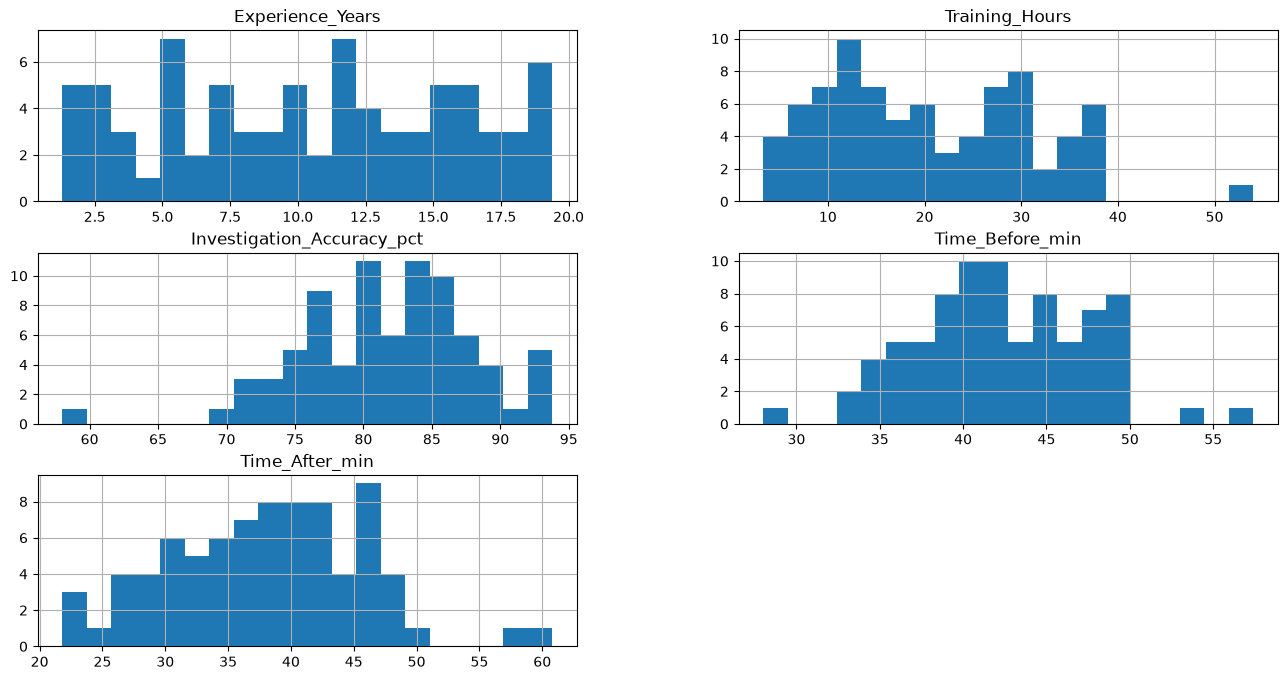

In [9]:
# Histograms for the distribution of each numeric variable
df.hist(figsize=(16, 8), bins=20)

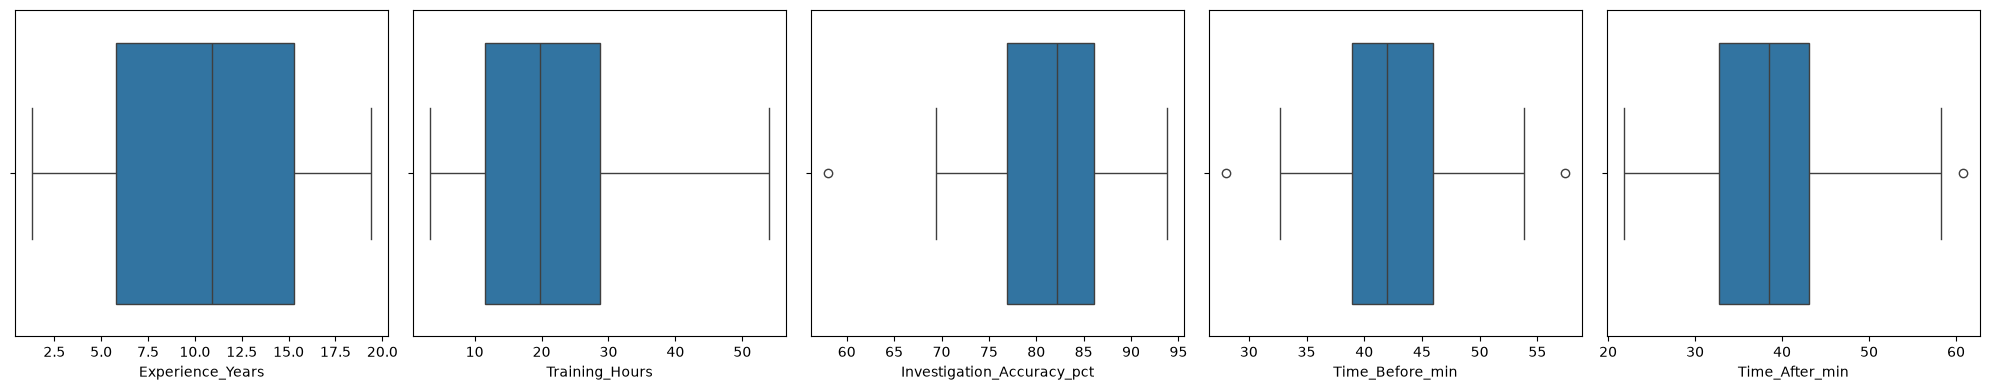

In [10]:
# Boxplots to check each numeric variable for outliers
cols = df.drop(columns='Employee_ID')
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes.flat, cols, strict=True):
    sns.boxplot(x=df[col], ax=ax)
plt.tight_layout()

## Question 1: Understanding Relationships between Variables

### a) Calculate and interpret the sample covariance between training hours and investigation accuracy. Explain why covariance alone is insufficient for comparing the strength of relationships.

The sample covariance of Training Hours and Investigation Accuracy is 31.10. It is a positive number, they have a positive relationship, with the tendency that more training hours is associated with higher investigation accuracy. The sample covariance alone is not enough to tell us the strength of the relationship as the number is the two units multiplied together, hours by percentage points in this case. This value is not clearly interpretable and is not easily comparable with other values because it varies based on the units used to calculate it. This also means there's no indication whether the value is big or small, and no way to compare across variables. This is why correlation is often used to examine the relationship between variables.

In [11]:
df['Training_Hours'].cov(df['Investigation_Accuracy_pct'])

np.float64(31.095104430379752)

### b) Calculate the Pearson and Spearman correlation coefficients for training hours and investigation accuracy. Interpret their direction and strength.
n = 80  
Pearson correlation between the variables is 0.46.  
Spearman correlation between the variables is 0.66.  

These positive values indicate that the variables are positively correlated, with Pearson indicating moderate correlation and Spearman indicating a strong correlation. Both are statistically significant with p-values close to 0, and so the correlation is unlikely by chance alone. The higher spearman correlation could indicate that the relationship between the two is not strictly linear, but may have a more complex relationship. Pearson is more sensitive to outliers, and the relationship may be monotonic but not linear, so it may underestimate the relationship. This is because Pearson measures how closely the points follow a straight line whereas Spearman measures rank consistency.

In [12]:
df.corr(numeric_only=True, method='pearson')

,Experience_Years,Training_Hours,Investigation_Accuracy_pct,Time_Before_min,Time_After_min
Experience_Years,1.000000,-0.039728,0.326624,-0.308468,-0.331235
Training_Hours,-0.039728,1.000000,0.455721,0.106043,0.001693
Investigation_Accuracy_pct,0.326624,0.455721,1.000000,-0.215295,-0.308203
Time_Before_min,-0.308468,0.106043,-0.215295,1.000000,0.784264
Time_After_min,-0.331235,0.001693,-0.308203,0.784264,1.000000


In [13]:
df.corr(numeric_only=True, method='spearman')

,Experience_Years,Training_Hours,Investigation_Accuracy_pct,Time_Before_min,Time_After_min
Experience_Years,1.000000,-0.024100,0.300517,-0.349230,-0.359425
Training_Hours,-0.024100,1.000000,0.661779,0.123625,-0.010825
Investigation_Accuracy_pct,0.300517,0.661779,1.000000,-0.205130,-0.289387
Time_Before_min,-0.349230,0.123625,-0.205130,1.000000,0.761921
Time_After_min,-0.359425,-0.010825,-0.289387,0.761921,1.000000


In [14]:
print(stats.pearsonr(df['Training_Hours'], df['Investigation_Accuracy_pct']))
print(stats.spearmanr(df['Training_Hours'], df['Investigation_Accuracy_pct']))

PearsonRResult(statistic=np.float64(0.4557210198192143), pvalue=np.float64(2.1585643446322432e-05))
SignificanceResult(statistic=np.float64(0.6617786688177901), pvalue=np.float64(2.334891573456222e-11))


### c) Produce a suitable scatterplot and assess whether the relationship appears linear, monotonic, or neither.
The relationship is roughly linear and monotonic. Overall, there is an upward trend, and the data points spread out, with a range of ~20% between them. One extreme outlier exists with a high amount of training hours and very low accuracy overall at 54 hours training, and 58% accuracy.  
  
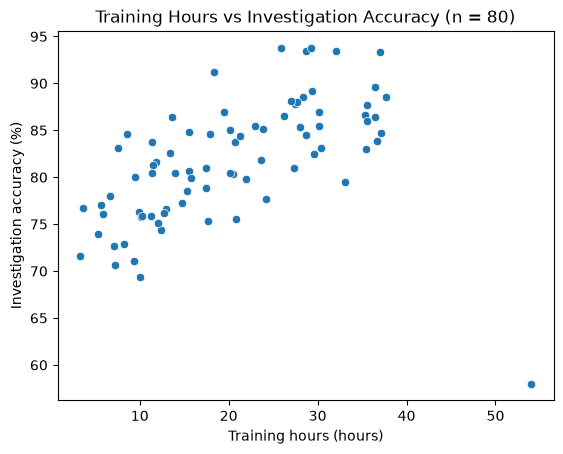

[Text(0.5, 0, 'Training hours (hours)'),
 Text(0, 0.5, 'Investigation accuracy (%)'),
 Text(0.5, 1.0, 'Training Hours vs Investigation Accuracy (n = 80)')]

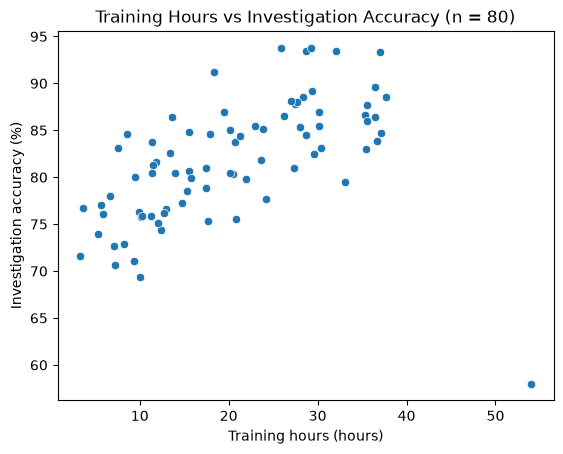

In [15]:
ax = sns.scatterplot(data=df, x='Training_Hours', y='Investigation_Accuracy_pct')
ax.set(
    xlabel='Training hours (hours)',
    ylabel='Investigation accuracy (%)',
    title='Training Hours vs Investigation Accuracy (n = 80)',
)

### d) Explain which correlation measure is more appropriate in this setting, taking account of outliers, measurement scales, and the observed relationship. Discuss whether the relationship establishes causation.

Spearman is the more appropriate correlation measure. 
- The outlier is quite different from the other points, pulling Pearson down while Spearman's ranking is more robust to it. This factor impacts Pearson's capability to accurately measure correlation. 
- The variables both use ratio measurements scales, so this does not impact Pearson. 
- The observed relationship is approximately linear and monotonic, so Pearson could be suitable.
- Training was not randomly assigned, and accuracy was only measured after training, so there is no baseline to compare with.
- The relationship does not establish causation. Causation could lie with many other factors outside the range of this data, such as sleep hours, workload, case difficulty, etc. Correlation is clear, but causation is unproven.

## Question 2: Did the Training Programme Improve Investigation Efficiency?
The dataset (.csv file) includes investigation times for comparable tasks undertaken by the same employees before and after training. Define each paired difference as `Time_Before_min` − `Time_After_min`, so positive values indicate reduced investigation time.

### a) Define the paired differences, population of interest, null hypothesis, and alternative hypothesis. Explain why an independent-samples t-test would be inappropriate.

- Paired differences for each employee = Time_Before_min − Time_After_min, in minutes. Positive is faster, negative is slower. The differences in time show that generally time improved by 4.39 minutes, but for certain employees decreased in performance, with a low of -7 minutes.  

- The population of interest is all the investigators that finish the training programme. μ_d is the mean paired difference for this population.  

- Hypotheses:  
H0: μ_d = 0 The null hypothesis is that mean investigation time is the same before and after training.  
H1: μ_d ≠ 0 The alternative hypothesis is that mean investigation time changed after training, either positively or negatively.  
A two-sided test will be applied as time can increase or decrease.

Independent t-tests aren't appropriate because the two measurements are dependent. The samples use the same 80 people so they're dependent. Using an independent t-test will have errors as it keeps the differences between employees, inflating the variability and diminishing the effect.

In [16]:
df['Time_Diff_min'] = df['Time_Before_min'] - df['Time_After_min']
df['Time_Diff_min'].describe()

count    80.000000
mean      4.386250
std       4.854901
min      -7.000000
25%       0.500000
50%       5.050000
75%       7.100000
max      16.700000
Name: Time_Diff_min, dtype: float64

### b) Check whether a paired t-test is appropriate, using diagnostics for the distribution of within-employee differences and considering independence between employees. Explain limitations of the assumptions.

Overall, a paired t-test is appropriate. Here we will examine the reasoning.

The number of samples is 80, meaning the central limit theorem will apply, so a  t-test can be robust to deviations from normality.

We must also check the data for normality. We see:
- The histogram has a roughly symmetrical shape, with no strong skew or extreme values.
- The Q-Q plot's points roughly follow the reference line, consistent with normality.
- Shapiro-Wilk test results at W = 0.989, p = 0.719, demonstrating no evidence against normality.

We must also assume from the data design that each employee is working independently. Each employee has a unique identifier that can indicate this.

There are limitations to our examination of the data: 
- Shapiro-Wilk does not confirm normality, simply fail to find evidence against it.
- The Q-Q plot is only a visual indicator, not confirmation of normality.
- Independence must be assumed, we cannot test it. If the employees work on teams, sharing cases, etc, the data is not truly independent.  
  

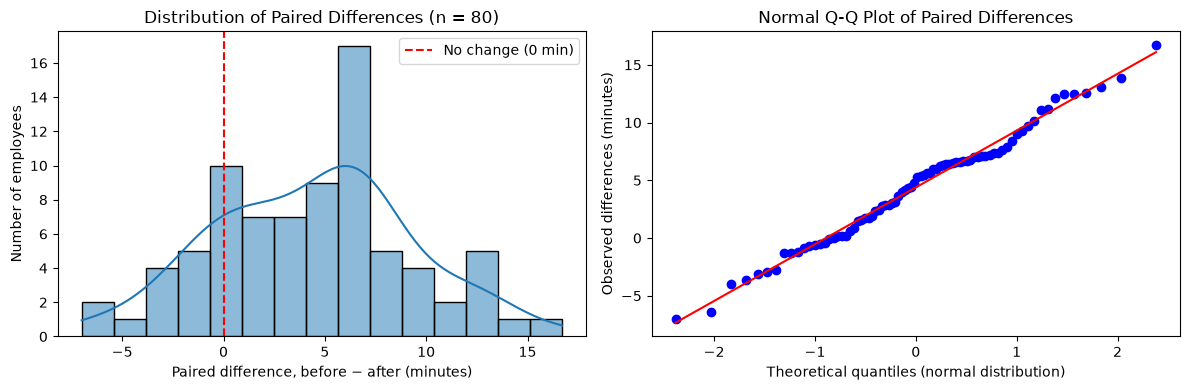

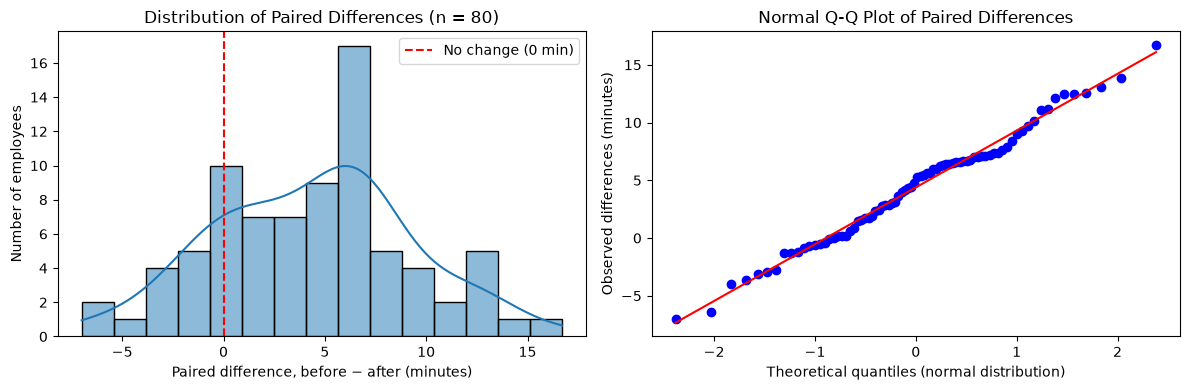

In [17]:
# Distribution of the paired differences: histogram and Q-Q plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=df, x='Time_Diff_min', bins=15, kde=True, ax=axes[0])
axes[0].axvline(0, color='red', linestyle='--', label='No change (0 min)')
axes[0].set(
    xlabel='Paired difference, before − after (minutes)',
    ylabel='Number of employees',
    title='Distribution of Paired Differences (n = 80)',
)
axes[0].legend()

stats.probplot(df['Time_Diff_min'], dist='norm', plot=axes[1])
axes[1].set(
    xlabel='Theoretical quantiles (normal distribution)',
    ylabel='Observed differences (minutes)',
    title='Normal Q-Q Plot of Paired Differences',
)
plt.tight_layout()

In [18]:
# Shapiro-Wilk test of normality on the paired differences
w, p = stats.shapiro(df['Time_Diff_min'])
print(w, p)

0.988822426294849 0.7192381343095888


### c) Perform a paired t-test at the 5% significance level. Report the t-statistic, degrees of freedom, p-value, estimated mean paired difference, and its 95% confidence interval. Interpret the result in minutes. If assumptions are questionable, briefly describe a defensible alternative.

Results:
- t-statistic: t = 8.08
- Degrees of freedom: df = 79
- p-value: p < 0.001 (6.1e-12)
- Mean paired difference: 4.39 minutes
- 95% confidence interval: 3.31 to 5.47 minutes

The p-value is below 0.05, so we reject the null hypothesis as investigation time fell. On average, investigations took 4.39 minutes less after training, with the confidence interval sitting between 3.31 and 5.47 minutes.  I do not think the assumptions are questionable as the checks in the previous section were satisfactory. An alternative, in the case of questionable assumptions, would be the Wilcoxon signed-rank test, which does not assume normality.

In [19]:
# Paired t-test with 95% confidence interval for the mean difference
result = stats.ttest_rel(df['Time_Before_min'], df['Time_After_min'])
ci = result.confidence_interval(confidence_level=0.95)
print(f't({result.df:.0f}) = {result.statistic:.2f}, p = {result.pvalue:.1e}')
print(f"Mean difference = {df['Time_Diff_min'].mean():.2f} minutes, 95% CI {ci.low:.2f} to {ci.high:.2f}")
print(f"Mean time before = {df['Time_Before_min'].mean():.2f}, after = {df['Time_After_min'].mean():.2f}")

t(79) = 8.08, p = 6.1e-12
Mean difference = 4.39 minutes, 95% CI 3.31 to 5.47
Mean time before = 42.32, after = 37.93


### d) Explain whether the findings demonstrate that training caused the observed change. Identify one plausible alternative explanation.

No, the findings do not demonstrate causation. The results demonstrate that investigation time fell after training but other factors cannot be ruled out. There is no control group data for comparison of results. An alternative explanation could be improvement through practice alone, with more tasks and cases equating to more experience and improved efficiency.

## Question 3: How Reliable Is the Fraud Detection System?
For this question, assume the following hypothetical system characteristics:

| Parameter | Value |
|:--|:--|
| Fraud prevalence | 2% |
| Sensitivity (true-positive rate) | 90% |
| Specificity (true-negative rate) | 95% |
| Transactions assessed | 10,000 |

### a) Define the events and calculate the probability that a randomly selected transaction is flagged.

Events:
- F = the transaction is fraudulent; not F = the transaction is legitimate
- A = the transaction is flagged for alert

Therefore:
- P(F) = 0.02, so P(not F) = 1 - 0.02 = 0.98
- Sensitivity, P(A | F) = 0.90
- Specificity, P(not A | not F) = 0.95, so the false-positive rate is P(A | not F) = 1 - 0.95 = 0.05  

Law of total probability:  
P(A) = P(A | F) x P(F) + P(A | not F) x P(not F)  
P(A) = (0.90 x 0.02) + (0.05 x 0.98)  
P(A) = 0.018 + 0.049 = 0.067

The probability that a randomly selected transaction is flagged is 0.067 (6.7%).

### b) Use Bayes’ theorem to calculate the probability that a flagged transaction is fraudulent. Show your reasoning and calculations.

Bayes' theorem:  
P(F | A) = P(A | F) x P(F) / P(A)  
P(F | A) = (0.90 x 0.02) / 0.067  
P(F | A) = 0.018 / 0.067 = 0.269

Sensitivity is the probability of an alert when fraud occurs; Bayes' theorem calculates the opposite: the probability of fraud when there is an alert. The probability that a transaction is both fraudulent and flagged is 0.018, and the probability that it is flagged for any reason is 0.067.

The probability that a flagged transaction is fraudulent is 0.269 (26.9%).

### c) Construct a confusion matrix of expected numbers of true positives, false positives, true negatives, and false negatives for 10,000 transactions.

| | Fraudulent | Legitimate | Total |
|:--|--:|--:|--:|
| **Flagged** | TP = 180 | FP = 490 | 670 |
| **Not flagged** | FN = 20 | TN = 9,310 | 9,330 |
| **Total** | 200 | 9,800 | 10,000 |

In [20]:
prevalence = 0.02
sensitivity = 0.90
specificity = 0.95
n_transactions = 10_000

p_flag = sensitivity * prevalence + (1 - specificity) * (1 - prevalence)
p_fraud_given_flag = sensitivity * prevalence / p_flag
print(f'P(A) = {p_flag:.3f}')
print(f'P(F | A) = {p_fraud_given_flag:.3f}')

fraud = n_transactions * prevalence
legit = n_transactions - fraud
tp = sensitivity * fraud
fn = fraud - tp
fp = (1 - specificity) * legit
tn = legit - fp

confusion = pd.DataFrame(
    {
        'Fraudulent': [tp, fn, fraud],
        'Legitimate': [fp, tn, legit],
        'Total': [tp + fp, fn + tn, n_transactions],
    },
    index=['Flagged', 'Not flagged', 'Total'],
)
confusion.round().astype(int)

P(A) = 0.067
P(F | A) = 0.269


,Fraudulent,Legitimate,Total
Flagged,180,490,670
Not flagged,20,9310,9330
Total,200,9800,10000


### d) Explain how the system can have 90% sensitivity while a substantial proportion of its alerts are false positives.

Sensitivity is the true positive rate, so it only measures the number of fraudulent transactions that are actually caught. Fraud is only 2% of transactions, so one of every 50 transactions is fraudulent. For example,  this means a 5% false-positive rate will produce 490 false alerts for 180 true alerts, leaving 490 out of 670 (73%), alerts to be false positives, even with 90% sensitivity.

## Question 4: From Probability to Decision-Making
Management must choose whether to investigate a flagged transaction. Assume the following hypothetical losses (monetary units per transaction):

| Decision | Fraudulent transaction | Legitimate transaction |
|:--|:--|:--|
| Investigate | 100 | 100 |
| Do not investigate | 2,000 | 0 |

### a) Using the posterior fraud probability from Question 3, calculate the expected loss of each decision for a flagged transaction.

p = 0.2687  
1 - p = 0.7313

The expected loss of each decision is the loss for each section of the table, weighted by the probability of that section.

Investigate:  
E[Loss | Investigate] = 100p + 100(1 - p)  
E[Loss | Investigate] = 100 x (18/67) + 100 x (49/67) = 100

Do not investigate:  
E[Loss | Do not investigate] = 2000p + 0(1 - p)  
E[Loss | Do not investigate] = 2000 x (18/67) + 0 x (49/67) = 537.31

Investigating costs 100 in all cases, so its expected loss is 100 for any value of p. Not investigating a legitimate transaction costs 0 but costs 2,000 for a fraudulent one, therefore its expected loss is 2,000 multiplied by the probability of fraud.

For a flagged transaction, investigating has an expected loss of 100 and 537 if it is not investigated.

In [21]:
# Expected loss of each decision for a flagged transaction
loss_investigate = 100 * p_fraud_given_flag + 100 * (1 - p_fraud_given_flag)
loss_ignore = 2000 * p_fraud_given_flag + 0 * (1 - p_fraud_given_flag)
print(f'Investigate: {loss_investigate:.2f}')
print(f'Do not investigate: {loss_ignore:.2f}')

Investigate: 100.00
Do not investigate: 537.31


### b) Recommend the decision that minimises expected loss. Explain why this may differ from a simple rule that investigates only if fraud is more likely than not.

The recommendation is to always investigate a flagged transaction as it has the lower expected loss of 100 vs 537. A rule that investigates only when fraud is more likely than not would treat each mistake as equally costly, but missing fraud is twenty times more expensive than investigation. The approach to investigate examines each outcome by both cost and probability , indicating investigation is worthwhile even when fraud is less likely.

### c) Derive the posterior probability threshold above which investigation has lower expected loss than not investigating.

p is  the posterior probability that a flagged transaction is fraudulent.

E[Loss | Investigate] = 100  
E[Loss | Do not investigate] = 2000p

The threshold is the value of p at which the two expected losses are equal:  
100 = 2000p  
p = 100 / 2000 = 0.05

Investigation has the lower expected loss when 100 < 2000p, which is when p > 0.05.

The threshold is p = 0.05. Above a 5% posterior probability of fraud, investigating has the lower expected loss. Below this value, investigating has a higher expected loss and at exactly 5%, the two are equal.

### d) Identify one practical cost, impact, or constraint omitted from the simplified decision model.

490 of 670 total flags are false-positives, which is quite high. This could create issues with customer goodwill as many customers may become frustrated with their legitimate transactions being frequently flagged for examination, consequentially potentially losing customers.

## Question 5: Sensitivity and Robustness

### a) Recalculate the probability of fraud given a positive alert if fraud prevalence falls to 0.5%, while sensitivity and specificity remain unchanged. Compare your answer with Question 3 and explain the change.

Given:
- P(F) = 0.005, so P(not F) = 1 - 0.005 = 0.995
- Sensitivity = 0.90
- Specificity = 0.95

Law of total probability:  
P(A) = P(A | F) x P(F) + P(A | not F) x P(not F)  
P(A) = (0.90 x 0.005) + (0.05 x 0.995)  
P(A) = 0.0045 + 0.04975 = 0.05425

Bayes' theorem:  
P(F | A) = P(A | F) x P(F) / P(A)  
P(F | A) = 0.0045 / 0.05425 = 0.083

The probability that a flagged transaction is fraudulent reduces from 26.9% to 8.3%.

The change is caused by the lower base rate. Comparing the two cases per 10,000 transactions:

| | Question 3 (2% prevalence) | 0.5% prevalence |
|:--|--:|--:|
| Fraudulent transactions | 200 | 50 |
| True positives (90% of frauds) | 180 | 45 |
| Legitimate transactions | 9,800 | 9,950 |
| False positives (5% of legitimate) | 490 | 497.5 |
| Total alerts | 670 | 542.5 |
| Share of alerts that are fraud | 26.9% | 8.3% |

An alert is now much less likely to be fraud. There are now only 45 true positives compared to 180, but the number of false positives remains similar. The proportion of false alerts to treu positives increases significantly due to the lower base rate.

In [22]:
prevalence_low = 0.005

p_flag_low = sensitivity * prevalence_low + (1 - specificity) * (1 - prevalence_low)
p_fraud_low = sensitivity * prevalence_low / p_flag_low
print(f'P(A) = {p_flag_low:.5f}')
print(f'P(F | A) = {p_fraud_low:.3f} (was {p_fraud_given_flag:.3f})')

fraud_low = n_transactions * prevalence_low
legit_low = n_transactions - fraud_low
print(f'Fraudulent: {fraud_low:.0f}, true positives: {sensitivity * fraud_low:.1f}')
print(f'Legitimate: {legit_low:.0f}, false positives: {(1 - specificity) * legit_low:.1f}')

P(A) = 0.05425
P(F | A) = 0.083 (was 0.269)
Fraudulent: 50, true positives: 45.0
Legitimate: 9950, false positives: 497.5


### b) Identify and justify one potentially influential observation in the relationship analysed in Question 1. Recalculate Pearson and Spearman correlations excluding only that observation, compare them with the full-sample results, and discuss robustness. Report the observation ID and both sample sizes; retain it in the main analysis unless exclusion is defensible.

| | n | Pearson r | Spearman ρ |
|:--|--:|--:|--:|
| All employees | 80 | 0.46 | 0.66 |
| Excluding E037 | 79 | 0.71 | 0.73 |

The influential observation is the outlier with staff id E037, with 54 training hours and 58% accuracy. This instance has the most training but the worst accuracy. Both variables are extreme and they run contrary to the observed trend. Consequently, it can heavily impact the correlation.

Excluding observation E037 raises both Pearson and Spearman correlation. Pearson sharply increases from 0.46 to 0.71, while Spearman increases only slightly from 0.66 to 0.73. This demonstrates that earlier choice of Spearman was a good judgement, as Spearman is robust to this outlier while Pearson is heavily impacted.

The values of E037 are plausible despite being extreme, and we have no evidence of a data entry error, so I have chosen to retain the item in the analysis.

In [23]:
df.loc[[df['Training_Hours'].idxmax()]]

,Employee_ID,Experience_Years,Training_Hours,Investigation_Accuracy_pct,Time_Before_min,Time_After_min,Time_Diff_min
36,E037,5.7,54.0,58.0,48.7,47.0,1.7


In [24]:
df_excl = df[df['Employee_ID'] != 'E037']
x, y = 'Training_Hours', 'Investigation_Accuracy_pct'

print(len(df), df[x].corr(df[y]), df[x].corr(df[y], method='spearman'))
print(len(df_excl), df_excl[x].corr(df_excl[y]), df_excl[x].corr(df_excl[y], method='spearman'))

80 0.4557210198192143 0.6617786688177901
79 0.7131722145872897 0.7257002351482935


## Question 6: Evidence-Based Management Recommendation
Write a management brief of no more than 300 words that:
- a) states whether the employee programme appears effective, separating statistical evidence from causal claims;
- b) explains what the correlation findings establish and what remains uncertain;
- c) recommends whether flagged transactions should normally trigger investigations under the stated loss model;
- d) identifies one major limitation and one specific next analytical or operational action.


**Management Brief:**  
a) Findings indicate that the programme appears effective with investigation times on tasks decreasing by 4.4 minutes (95% CI 3.3-5.5) on average after training. A paired t-test (p-value < 0.001, n= 80) indicates that there is statistical significance in the results. However, there is not enough evidence to state that the programme caused the fall as there was no control group and the staff not assigned randomly. This means that other changes, such as practice and experience over time could explain the time decrease.  
  
b) Correlations demonstrate that employees with more training hours tend to be more accurate (Spearman 0.66), but this only establishes association. It does not clarify if training actually improves accuracy as it was measured only after training, and the exact strength of the correlation remains unclear due to one outlier employee that has a large effect on Pearson.
  
c) Flagged transactions should normally be investigated because of the cost balance. As long as the probability of fraud is above 5%, investigation is the better practice. Missed fraudulent transactions cost 2000 against 100 for investigation, with a 26.9% probability of fraud there is only a 100 expected loss per alert compared with 537 for not investigating. Even with a low prevalence of fraud at 0.5%, 8.3% od alerts would still be fraudulent, above the 5% threshold.
  
d) The primary limitation is the lack of a control group, without untrained staff to compare results against, meaning that other factors could explain the trends in the data. The investigation accuracy is recorded only after training but we have no baseline. The next step would be to compare accuracy both before and after training, with trained and untrained staff to see if the training itself has a material effect.

## AI Use Disclaimer
Claude Opus 5.5 was used for Markdown formatting, grammatical correction, debugging code, technical explanation, code arithmetic, string formatting, and critical process analysis.